# Chapitre 9 - Cours 6 : les services de coordination

Implémenter soi-même un algorithme de consensus est une très mauvaise idée : les cours
précédents ont montré combien les détails comptent. La plupart des systèmes distribués
**sous-traitent** donc le consensus à un **service de coordination** : ZooKeeper, etcd ou
Consul. Ce notebook modélise un tel service (`cs.CoordService` : révisions, baux, clés
éphémères et séquentielles, surveillances) et l'utilise pour les usages du livre : verrous
et baux avec jetons de clôture, détection de pannes, élection de leader, répartition du
travail entre nœuds, découverte de services. Il couvre la section *Membership and Coordination Services* (*Allocating work to nodes*, *Service discovery*, *Membership services*).

**Plan.**

1. Ce qu'est un service de coordination.
2. Verrous, baux et jetons de clôture.
3. Détection de pannes : sessions et clés éphémères.
4. Notifications et élection de leader.
5. Répartir le travail entre les nœuds.
6. Découverte de services.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Ce qu'est un service de coordination (section *Membership and Coordination Services*)

Vu de loin, ZooKeeper ou etcd ressemblent à un magasin clé-valeur. Mais ils ne sont pas
faits pour stocker des données volumineuses ou absorber un fort débit d'écritures : ils
servent à **coordonner les nœuds d'un autre système distribué**. Ils gardent une petite
quantité de données, qui tient en mémoire (tout en étant écrite sur disque pour la
durabilité), répliquée sur quelques nœuds par un algorithme de consensus tolérant aux
pannes (Zab pour ZooKeeper, Raft pour etcd). Ils s'inspirent du service de verrous
**Chubby** de Google. HBase, Kafka ou Hadoop YARN, par exemple, s'appuient sur ZooKeeper.

Au consensus (qui fournit des opérations linéarisables, dont le CAS), ils ajoutent des
fonctions très utiles pour construire des systèmes distribués :

- **verrous et baux** : si plusieurs nœuds tentent d'acquérir le même bail, un seul réussit ;
- **clôture** (fencing) : chaque écriture reçoit un identifiant croissant (zxid et
  cversion chez ZooKeeper, numéro de révision chez etcd), utilisable comme jeton ;
- **détection de pannes** : chaque client garde une **session** entretenue par des
  battements ; si la session expire, ses baux sont libérés et ses clés **éphémères**
  disparaissent ;
- **notifications** : un client peut **surveiller** (watch) une clé et être prévenu de ses
  changements, sans interroger le service en boucle.

La détection de pannes et les notifications ne demandent pas de consensus ; les
opérations atomiques et la clôture, si.

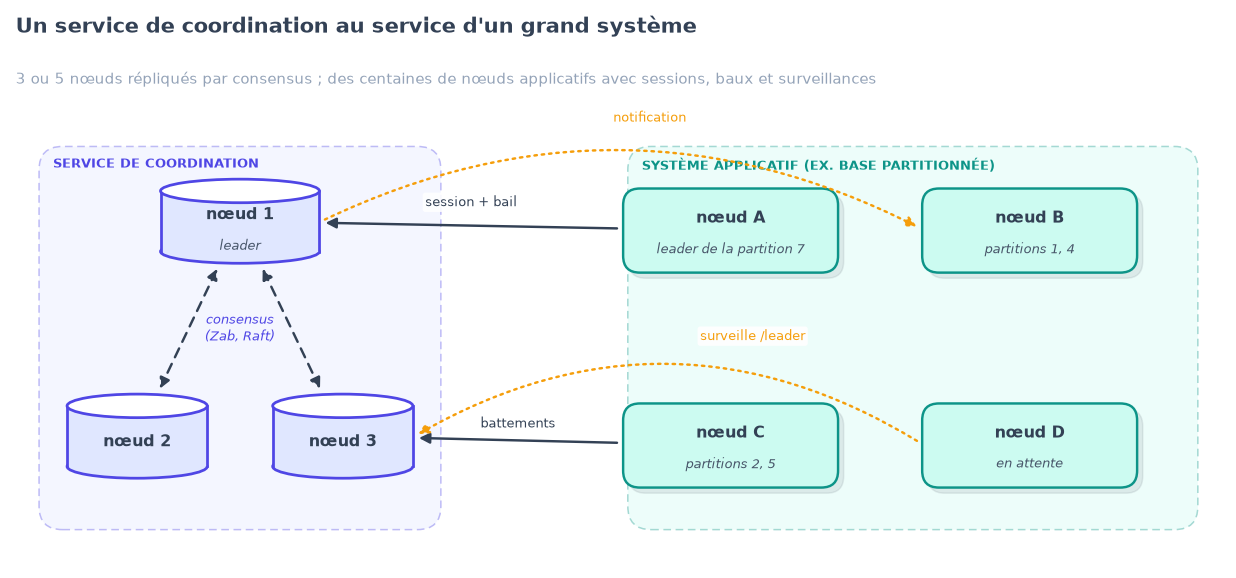

In [2]:
d = Diagram(13, 5.0, title="Un service de coordination au service d'un grand système",
            subtitle="3 ou 5 nœuds répliqués par consensus ; des centaines de nœuds applicatifs avec sessions, baux et surveillances")
d.group(0.3, 0.4, 4.6, 4.5, "service de coordination", color=INDIGO)
d.box("z1", 2.45, 3.7, "nœud 1", sub="leader", color=INDIGO, kind="db", w=1.7, h=0.9)
d.box("z2", 1.35, 1.4, "nœud 2", color=INDIGO, kind="db", w=1.5, h=0.9)
d.box("z3", 3.55, 1.4, "nœud 3", color=INDIGO, kind="db", w=1.5, h=0.9)
d.arrow("z1", "z2", style="dashed", both=True)
d.arrow("z1", "z3", style="dashed", both=True)
d.note(2.45, 2.55, "consensus\n(Zab, Raft)", color=INDIGO, fontsize=8.5)
d.group(6.6, 0.4, 12.7, 4.5, "système applicatif (ex. base partitionnée)", color=TEAL)
apps = [("a1", 7.7, 3.6, "nœud A", "leader de la partition 7"), ("a2", 10.9, 3.6, "nœud B", "partitions 1, 4"),
        ("a3", 7.7, 1.3, "nœud C", "partitions 2, 5"), ("a4", 10.9, 1.3, "nœud D", "en attente")]
for name, x, y, t, s in apps:
    d.box(name, x, y, t, sub=s, color=TEAL, w=2.3, h=0.9)
d.arrow("a1", "z1", "session + bail", label_offset=(0, 0.25))
d.arrow("a3", "z3", "battements")
d.arrow("z1", "a2", "notification", color=AMBER, style="dotted", rad=-0.25, label_offset=(0.3, 0.35))
d.arrow("a4", "z3", "surveille /leader", style="dotted", color=AMBER, rad=0.3, label_offset=(0.9, 0.3))
d.show()

> **À retenir.** Un service de coordination = un petit magasin clé-valeur linéarisable
> répliqué par consensus, plus des baux, des sessions, des clés éphémères, des
> identifiants croissants et des notifications. On l'utilise pour coordonner, pas pour
> stocker.

## 2. Verrous, baux et jetons de clôture (section *Membership and Coordination Services*)

Un **verrou** s'implémente par un CAS « créer la clé `/verrou` si elle n'existe pas ». En
l'attachant à un **bail** de durée limitée, on évite qu'un client mort ne le garde pour
toujours : sans battement avant l'expiration, le bail est révoqué et la clé disparaît.
Mais comme on l'a vu au chapitre 8, un client peut être **suspendu** (pause du
ramasse-miettes, machine virtuelle gelée) plus longtemps que son bail, puis reprendre en
se croyant toujours détenteur du verrou. La parade est le **jeton de clôture** : le numéro
de révision de la création du verrou, croissant, que la ressource protégée vérifie à
chaque écriture. Rejouons la scène avec `cs.CoordService`.

In [3]:
svc = cs.CoordService()
stockage = {"max_jeton": 0, "journal": []}
def ecrire(client, jeton, t, valeur):
    ok = jeton >= stockage["max_jeton"]
    if ok:
        stockage["max_jeton"] = jeton
    stockage["journal"].append(dict(t=t, client=client, jeton=jeton, valeur=valeur, acceptée=ok))
    return ok

bail1 = svc.grant(10, now=0)
ok1, jeton1 = svc.create("/verrou", "client 1", bail1)
svc.keepalive(bail1, now=4)
attente = []
svc.watch("/verrou", lambda kind, key, rev: attente.append((kind, rev)))     # le client 2 attend
ecrire("client 1", jeton1, 5, "a")
# pause du client 1 de t = 6 à t = 26 : plus de battements
svc.expire(now=14)                    # le bail expire à 4 + 10 = 14
bail2 = svc.grant(10, now=14.5)
ok2, jeton2 = svc.create("/verrou", "client 2", bail2)
ecrire("client 2", jeton2, 17, "b")
ecrire("client 1", jeton1, 26, "a'")  # le client 1 se réveille et croit toujours tenir le verrou
print(f"jeton du client 1 : {jeton1} ; notification reçue par le client 2 : {attente} ; jeton du client 2 : {jeton2}")
pd.DataFrame(stockage["journal"])

jeton du client 1 : 1 ; notification reçue par le client 2 : [('delete', 2)] ; jeton du client 2 : 3


,t,client,jeton,valeur,acceptée
0,5,client 1,1,a,True
1,17,client 2,3,b,True
2,26,client 1,1,a',False


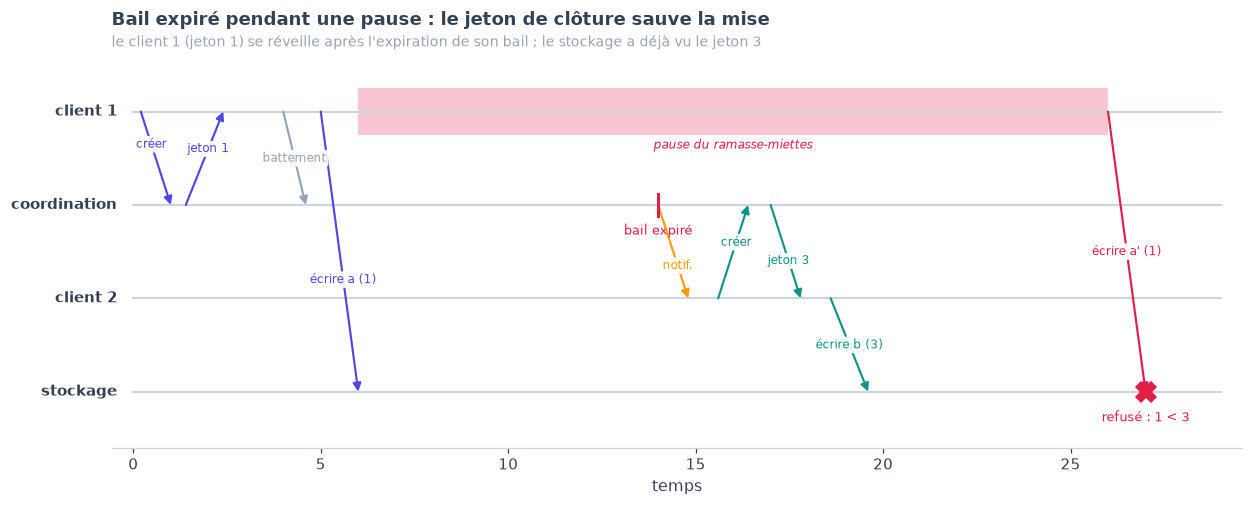

In [4]:
st = SpaceTime(["client 1", "coordination", "client 2", "stockage"], t_max=29, width=11.5,
               title="Bail expiré pendant une pause : le jeton de clôture sauve la mise",
               subtitle=f"le client 1 (jeton {jeton1}) se réveille après l'expiration de son bail ; le stockage a déjà vu le jeton {jeton2}")
st.msg("client 1", 0.2, "coordination", 1.0, "créer", color=INDIGO, label_pos=0.35)
st.msg("coordination", 1.4, "client 1", 2.4, f"jeton {jeton1}", color=INDIGO, label_pos=0.6)
st.msg("client 1", 4.0, "coordination", 4.6, "battement", color=GRAY)
st.msg("client 1", 5.0, "stockage", 6.0, f"écrire a ({jeton1})", color=INDIGO, label_pos=0.6)
st.span("client 1", 6.0, 26.0, "pause du ramasse-miettes", color=ROSE)
st.event("coordination", 14.0, "bail expiré", kind="tick", color=ROSE)
st.msg("coordination", 14.0, "client 2", 14.8, "notif.", color=AMBER, label_pos=0.65)
st.msg("client 2", 15.6, "coordination", 16.4, "créer", color=TEAL, label_pos=0.6)
st.msg("coordination", 17.0, "client 2", 17.8, f"jeton {jeton2}", color=TEAL, label_pos=0.6)
st.msg("client 2", 18.6, "stockage", 19.6, f"écrire b ({jeton2})", color=TEAL)
st.msg("client 1", 26.0, "stockage", 27.0, f"écrire a' ({jeton1})", color=ROSE)
st.event("stockage", 27.0, f"refusé : {jeton1} < {jeton2}", kind="crash")
st.show()

Sans le contrôle du jeton, l'écriture « zombie » du client 1 aurait écrasé celle du
client 2 alors que les deux croyaient tenir le verrou. Le service de coordination fournit
le jeton (sa révision croît à chaque écriture, grâce au journal partagé du consensus) ; la
ressource protégée doit **le vérifier**.

> **À retenir.** Verrou = CAS + bail. Un bail peut expirer pendant qu'un client dort :
> seule la vérification d'un jeton de clôture croissant (la révision du service) par la
> ressource protégée rend le verrou sûr.

## 3. Détection de pannes : sessions et clés éphémères (section *Membership and Coordination Services*)

Chaque client garde une **session** ouverte avec le service et envoie des battements. Une
coupure brève de connexion ou la panne d'un nœud du service ne la tue pas ; mais si aucun
battement n'arrive pendant la durée du bail (TTL), le service considère le client comme
mort, révoque ses baux et supprime ses clés **éphémères** (le nom vient de ZooKeeper).

Le choix de la TTL est le compromis du chapitre 8 : courte, une pause
ordinaire suffit à déclarer mort un client vivant (fausse détection : il perd ses verrous
et ses partitions) ; longue, un client vraiment mort garde ses ressources longtemps.
Modélisons des battements toutes les secondes et des pauses notables (ramasse-miettes,
gel de VM) environ toutes les 10 minutes, de durée log-normale de médiane 0,1 s mais à
queue lourde ($\sigma = 1$) : une session expire à tort si une pause dépasse TTL - 1 s.

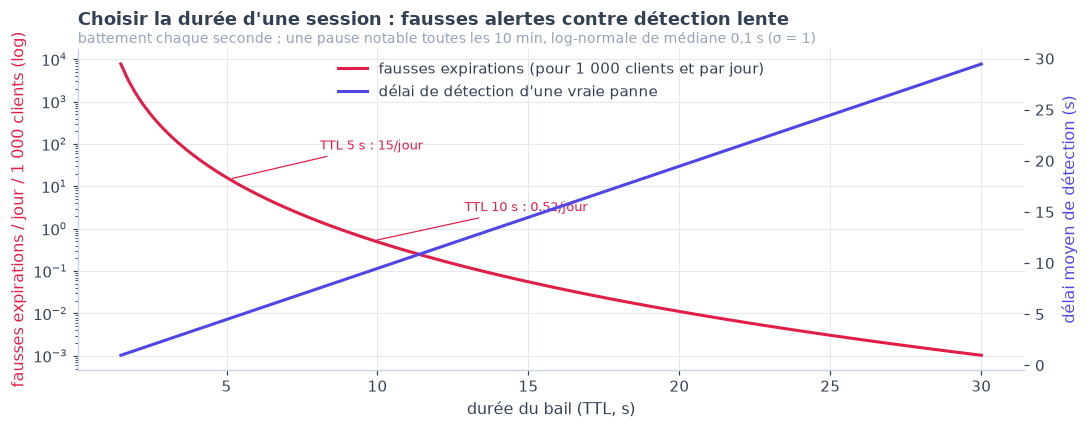

In [5]:
h = 1.0                                       # intervalle des battements (s)
from math import erfc, log, sqrt
def p_pause_plus_longue(x, mediane=0.1, sigma=1.0):
    return 0.5 * erfc(log(x / mediane) / (sigma * sqrt(2)))       # queue de la loi log-normale
ttl = np.linspace(1.5, 30, 120)
fausses = np.array([p_pause_plus_longue(t - h) for t in ttl]) * 6 * 24   # par client et par jour
detection = ttl - h / 2                       # délai moyen de détection d'une vraie panne
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ttl, fausses * 1000, color=ROSE, label="fausses expirations (pour 1 000 clients et par jour)")
ax.set_yscale("log")
ax.set_xlabel("durée du bail (TTL, s)")
ax.set_ylabel("fausses expirations / jour / 1 000 clients (log)", color=ROSE)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(ttl, detection, color=INDIGO, lw=2, label="délai de détection d'une vraie panne")
ax2.set_ylabel("délai moyen de détection (s)", color=INDIGO)
for t_, lab in [(5, "5 s"), (10, "10 s")]:
    k = np.argmin(abs(ttl - t_))
    ax.annotate(f"TTL {lab} : {fausses[k] * 1000:.2g}/jour", (ttl[k], fausses[k] * 1000), xytext=(ttl[k] + 3, fausses[k] * 1000 * 5),
                fontsize=8.5, color=ROSE, arrowprops=dict(arrowstyle="-", color=ROSE, lw=0.8))
ax.set_title("Choisir la durée d'une session : fausses alertes contre détection lente")
subtitle(ax, "battement chaque seconde ; une pause notable toutes les 10 min, log-normale de médiane 0,1 s (σ = 1)")
lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lines, [l.get_label() for l in lines], loc="upper center")
plt.tight_layout(); plt.show()

Chaque seconde de TTL supplémentaire retarde d'autant la détection d'une vraie panne,
mais divise les fausses expirations : de l'ordre de 16 par jour pour 1 000 clients avec
une TTL de 5 s, moins d'une avec 10 s ; la queue lourde des pauses fait qu'il en reste
même avec des TTL de plusieurs secondes. C'est pourquoi les sessions durent typiquement
quelques secondes à quelques dizaines de secondes, et pourquoi les jetons de clôture
restent indispensables : aucune TTL n'élimine les fausses détections.

> **À retenir.** Une session expire sans battement pendant la TTL ; ses clés éphémères
> disparaissent. La TTL arbitre entre fausses détections (courte) et lenteur de réaction
> (longue).

## 4. Notifications et élection de leader (section *Membership and Coordination Services*)

Un client peut demander à être notifié quand une clé change : il apprend ainsi qu'un autre
client a rejoint la grappe (il a écrit une clé) ou est mort (sa session a expiré et ses
clés éphémères ont disparu), sans interroger le service en boucle. Combinées aux clés
éphémères et séquentielles, les notifications donnent la **recette classique d'élection**
de ZooKeeper (et l'élection d'etcd) :

1. chaque candidat crée une clé **éphémère séquentielle** sous `/election/` ;
2. celui qui a le **plus petit** numéro est leader ;
3. les autres attendent. Variante naïve : tous surveillent le préfixe et relisent la
   liste à chaque changement. Variante soignée : chacun surveille **seulement son
   prédécesseur** immédiat.

Quand le leader meurt, sa clé disparaît et le suivant prend le relais. Comparons le
nombre de notifications envoyées par le service à chaque bascule.

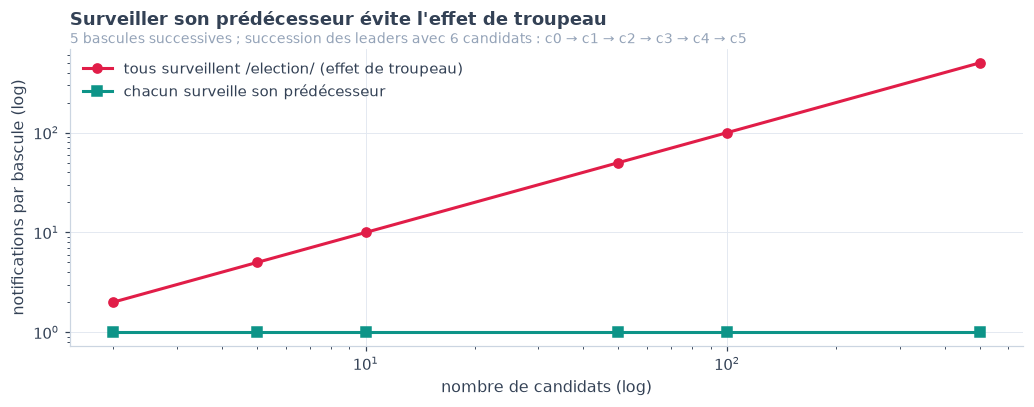

In [6]:
def election(n, variante, morts=5):
    svc = cs.CoordService()
    cles, leases, leaders = {}, {}, []
    def verifier(cand):
        vivantes = svc.keys("/election/")
        if cles[cand] not in vivantes:
            return
        if vivantes[0] == cles[cand]:
            leaders.append(cand)
        elif variante == "prédécesseur":
            pred = vivantes[vivantes.index(cles[cand]) - 1]
            svc.watch(pred, lambda kind, key, rev, c=cand: verifier(c))
    for i in range(n):
        c = f"c{i}"
        leases[c] = svc.grant(10, now=0)
        cles[c] = svc.create_sequential("/election/n-", c, leases[c])
    for c in cles:
        if variante == "prédécesseur":
            verifier(c)
        else:
            svc.watch("/election/", lambda kind, key, rev, c=c: verifier(c), prefix=True, once=False)
            verifier(c) if svc.keys("/election/")[0] == cles[c] else None
    base = svc.notifications
    for k in range(min(morts, n - 1)):
        svc.revoke(leases[leaders[-1]])        # le leader meurt : sa session expire
    return (svc.notifications - base) / min(morts, n - 1), leaders

ns = [2, 5, 10, 50, 100, 500]
res = {v: [election(n, v)[0] for n in ns] for v in ("naïve", "prédécesseur")}
_, chaine = election(6, "prédécesseur")
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(ns, res["naïve"], "o-", color=ROSE, label="tous surveillent /election/ (effet de troupeau)")
ax.plot(ns, res["prédécesseur"], "s-", color=TEAL, label="chacun surveille son prédécesseur")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nombre de candidats (log)"); ax.set_ylabel("notifications par bascule (log)")
ax.set_title("Surveiller son prédécesseur évite l'effet de troupeau")
subtitle(ax, f"5 bascules successives ; succession des leaders avec 6 candidats : {' → '.join(chaine)}")
ax.legend()
plt.tight_layout(); plt.show()

Dans la variante naïve, la mort du leader réveille **tous** les candidats, qui relisent
tous la liste (effet de troupeau, herd effect) : le coût d'une bascule croît avec le
nombre de candidats. En surveillant seulement son prédécesseur, une seule notification
suffit, et l'ordre de succession est fixé par les numéros séquentiels.

> **À retenir.** Clés éphémères + numéros séquentiels + notifications = élection de leader
> et détection de départs sans interrogation en boucle ; surveiller son seul prédécesseur
> rend la bascule indépendante du nombre de candidats.

## 5. Répartir le travail entre les nœuds (section *Allocating work to nodes*)

Deux usages typiques : **choisir un leader** parmi plusieurs instances d'un service (base à
leader unique, mais aussi ordonnanceur de tâches ou tout système avec état) ; et
**attribuer des partitions** d'une ressource (base, flux de messages, stockage de fichiers,
système d'acteurs) aux nœuds, en déplaçant une partie de la charge quand un nœud arrive et
en reprenant le travail d'un nœud qui part ou meurt. Simulons six travailleurs et 24
partitions : chaque travailleur s'inscrit par une clé éphémère sous `/workers/` ; un
coordinateur (élu comme en section 4) surveille ce préfixe et réécrit l'attribution dans
`/assign/`. Le travailleur w3 meurt à t = 40 (sa session expire après la TTL de 10 s) ;
w7 rejoint la grappe à t = 80.

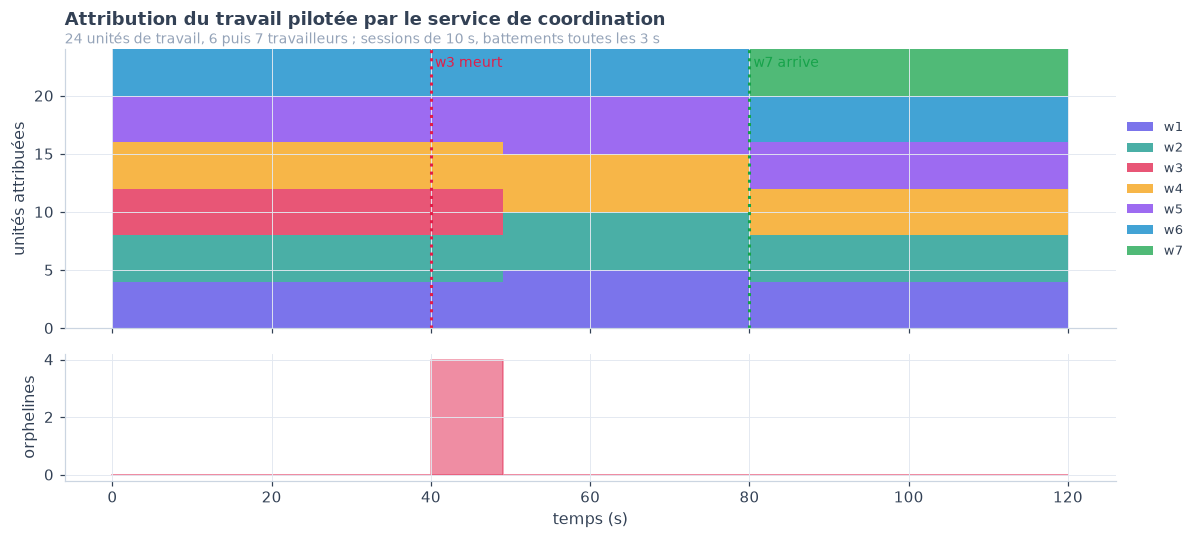

notifications envoyées au coordinateur : 8 ; révision finale : 200


In [7]:
svc = cs.CoordService()
workers, leases, morts = [f"w{i}" for i in range(1, 7)], {}, set()
unites = list(range(24))
assign = {}
def reequilibrer(*_):
    vivants = [k.split("/")[-1] for k in svc.keys("/workers/")]
    if not vivants:
        return
    for s_ in unites:                                   # reprendre les unités orphelines
        if assign.get(s_) not in vivants:
            assign[s_] = min(vivants, key=lambda w: (sum(v == w for v in assign.values()), w))
    cible = len(unites) // len(vivants)
    for w in vivants:                                   # donner sa part au nouveau venu
        while sum(v == w for v in assign.values()) < cible:
            donneur = max(vivants, key=lambda x: sum(v == x for v in assign.values()))
            s_ = next(s for s in unites if assign[s] == donneur)
            assign[s_] = w
    for s_ in unites:
        svc.put(f"/assign/{s_}", assign[s_])
svc.watch("/workers/", reequilibrer, prefix=True, once=False)
for w in workers:
    leases[w] = svc.grant(10, now=0)
    svc.put(f"/workers/{w}", "vivant", leases[w])
rows = []
for t in np.arange(0, 120.5, 0.5):
    if t == 40:
        morts.add("w3")
    if t == 80:
        workers.append("w7")
        leases["w7"] = svc.grant(10, now=t)
        svc.put("/workers/w7", "vivant", leases["w7"])
    for w in workers:
        if w not in morts and t % 3 == 0:
            svc.keepalive(leases[w], now=t)
    svc.expire(now=t)
    owners = {s_: assign[s_] for s_ in unites}
    rows.append(dict(t=t, orphelins=sum(1 for s_ in unites if owners[s_] in morts),
                     **{w: sum(v == w for v in owners.values()) for w in ["w1", "w2", "w3", "w4", "w5", "w6", "w7"]}))
A = pd.DataFrame(rows).set_index("t")
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
ax.stackplot(A.index, *[A[w] for w in ["w1", "w2", "w3", "w4", "w5", "w6", "w7"]], labels=["w1", "w2", "w3", "w4", "w5", "w6", "w7"],
             colors=[INDIGO, TEAL, ROSE, AMBER, VIOLET, SKY, GREEN], alpha=0.75, step="post")
ax.set_ylabel("unités attribuées")
ax.set_ylim(0, 24)
ax.axvline(40, color=ROSE, ls=":"); ax.axvline(80, color=GREEN, ls=":")
ax.text(40.5, 22.5, "w3 meurt", color=ROSE, fontsize=9); ax.text(80.5, 22.5, "w7 arrive", color=GREEN, fontsize=9)
ax.legend(ncol=1, loc="center left", fontsize=8.5, bbox_to_anchor=(1.0, 0.5))
ax.set_title("Attribution du travail pilotée par le service de coordination")
subtitle(ax, "24 unités de travail, 6 puis 7 travailleurs ; sessions de 10 s, battements toutes les 3 s")
ax2.fill_between(A.index, 0, A.orphelins, step="post", color=ROSE, alpha=0.5)
ax2.set_ylabel("orphelines"); ax2.set_xlabel("temps (s)")
plt.tight_layout(); plt.show()
print("notifications envoyées au coordinateur :", svc.notifications, "; révision finale :", svc.revision)

Après la mort de w3, ses quatre unités de travail restent **orphelines** pendant 9 s
(son dernier battement date de t = 39, sa session expire à t = 49) : personne ne les
traite. Puis la suppression de sa clé éphémère déclenche une notification, et le
coordinateur les redistribue (5, 5, 5, 5 et 4 unités). À l'arrivée de w7, il lui
transfère quatre unités prises aux plus chargés. Tout cela sans
intervention humaine. Ce n'est pas facile pour autant (des bibliothèques comme Apache
Curator fournissent des recettes au-dessus de ZooKeeper), mais c'est bien moins risqué
que d'implémenter son propre consensus.

**Pourquoi un petit service à part ?** Un service de coordination tourne sur un ensemble
**fixe** de 3 ou 5 nœuds, quelle que soit la taille du système qu'il coordonne. Faire voter
des milliers de nœuds serait terriblement inefficace : chaque décision coûterait un
message par nœud.

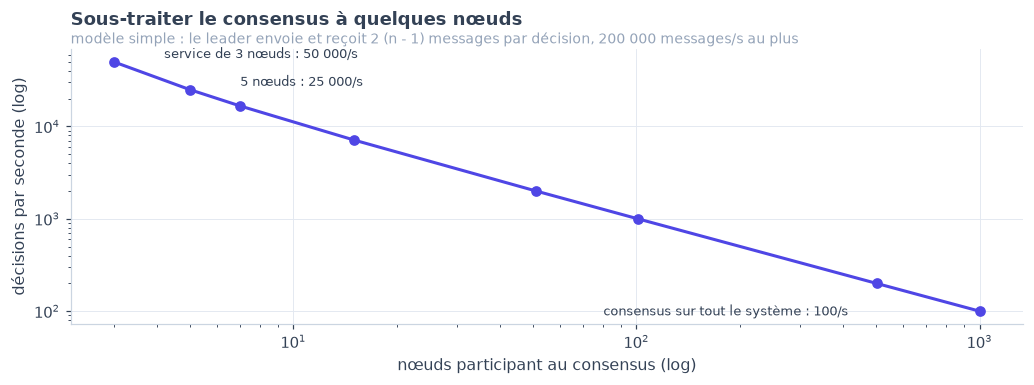

In [8]:
n_ = np.array([3, 5, 7, 15, 51, 101, 501, 1001])
capacite = 200_000                                    # messages par seconde traités par un leader
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(n_, capacite / (2 * (n_ - 1)), "o-", color=INDIGO)
for x, lab in [(3, "service de 3 nœuds"), (5, "5 nœuds"), (1001, "consensus sur tout le système")]:
    y = capacite / (2 * (x - 1))
    ax.annotate(f"{lab} : {y:,.0f}/s".replace(",", " "), (x, y), xytext=(x * 1.4, y * 1.1) if x < 1000 else (x * 0.08, y * 0.9),
                fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("nœuds participant au consensus (log)")
ax.set_ylabel("décisions par seconde (log)")
ax.set_title("Sous-traiter le consensus à quelques nœuds")
subtitle(ax, "modèle simple : le leader envoie et reçoit 2 (n - 1) messages par décision, 200 000 messages/s au plus")
plt.tight_layout(); plt.show()

Les données gérées ainsi changent **lentement** : « le nœud d'adresse 10.1.1.23 est leader
de la partition 7 » reste vrai des minutes ou des heures. Un service de coordination n'est pas fait
pour des données qui changent des milliers de fois par seconde : pour cela, une base de
données classique, ou un outil comme Apache BookKeeper pour répliquer l'état interne d'un
service qui change vite.

> **À retenir.** Élection d'un leader, attribution et réattribution du travail se
> construisent avec opérations atomiques, clés éphémères et notifications. Le service
> reste petit (3 ou 5 nœuds) et ne gère que des données qui changent lentement.

## 6. Découverte de services (sections *Service discovery* et *Membership services*)

ZooKeeper, etcd et Consul servent aussi à la **découverte de services** : trouver l'adresse
IP à laquelle joindre un service (chapitre 4). Dans un environnement où les
machines virtuelles vont et viennent, on ne connaît pas les adresses à l'avance : chaque
instance enregistre son adresse au démarrage (clé éphémère), et les clients la trouvent
dans le registre. La détection de pannes et les notifications du service s'y prêtent bien.

Mais le consensus est souvent **superflu** ici : la découverte de services n'a pas besoin
de linéarisabilité, elle doit surtout être **rapide et disponible** (sans elle, tout
s'arrête). On préfère donc mettre les résultats en **cache** avec une durée de vie (TTL),
comme le DNS et ses multiples niveaux de cache : un client qui n'arrive pas à joindre une
instance contourne son cache et relit la valeur fraîche. Quantifions le compromis : 50
instances dont la durée de vie moyenne est de 30 minutes, 10 000 clients.

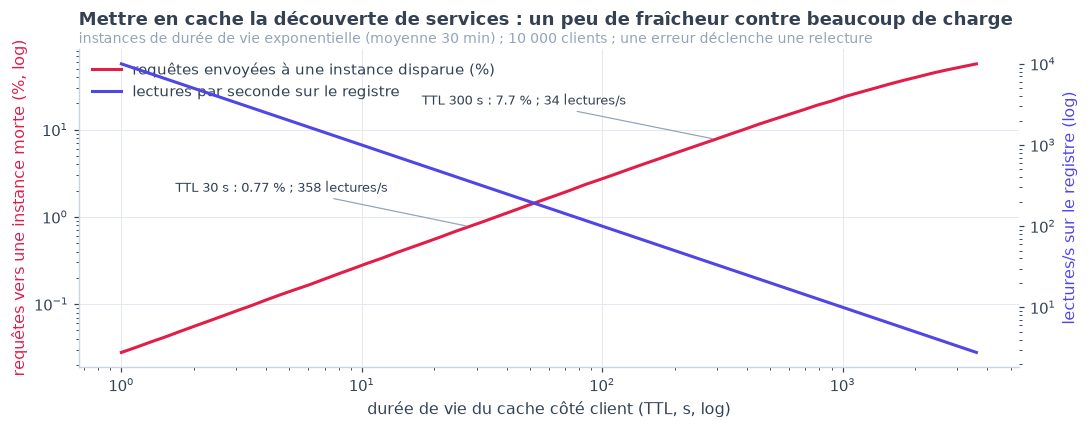

In [9]:
vie = 30 * 60                                 # durée de vie moyenne d'une instance (s)
T = np.geomspace(1, 3600, 60)
# part des adresses en cache mortes : une adresse lue il y a a secondes est morte avec probabilité 1 - exp(-a / vie)
morte = np.array([np.mean(1 - np.exp(-rng.uniform(0, t, 20000) / vie)) for t in T])
charge = 10_000 / T                           # lectures par seconde sur le registre
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(T, morte * 100, color=ROSE, label="requêtes envoyées à une instance disparue (%)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("durée de vie du cache côté client (TTL, s, log)")
ax.set_ylabel("requêtes vers une instance morte (%, log)", color=ROSE)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(T, charge, color=INDIGO, label="lectures par seconde sur le registre")
ax2.set_yscale("log"); ax2.set_ylabel("lectures/s sur le registre (log)", color=INDIGO)
for t_ in (30, 300):
    k = np.argmin(abs(T - t_))
    ax.annotate(f"TTL {t_} s : {morte[k] * 100:.2g} % ; {charge[k]:.0f} lectures/s", (T[k], morte[k] * 100),
                xytext=(T[k] * 0.06, morte[k] * 100 * 2.5), fontsize=8.5, color=SLATE,
                arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lines, [l.get_label() for l in lines], loc="upper left")
ax.set_title("Mettre en cache la découverte de services : un peu de fraîcheur contre beaucoup de charge")
subtitle(ax, "instances de durée de vie exponentielle (moyenne 30 min) ; 10 000 clients ; une erreur déclenche une relecture")
plt.tight_layout(); plt.show()

Avec une TTL de 30 s, moins de 1 % des requêtes visent une instance disparue (et sont
relancées après relecture), pour environ 350 lectures par seconde sur le registre au lieu d'une
lecture par requête. Pour ce genre d'usage, ZooKeeper propose des **observateurs**
(observers) : des répliques qui reçoivent le journal et gardent une copie des données sans
participer aux votes. Leurs lectures ne sont pas linéarisables (elles peuvent être en
retard), mais elles restent disponibles pendant une coupure réseau et augmentent le débit
de lecture sans ralentir le consensus. Si l'on utilise déjà le service pour des baux, des
verrous ou l'élection, s'en servir aussi pour la découverte est naturel : il sait déjà quel
nœud doit recevoir les requêtes.

**Services d'appartenance** (*Membership services*). ZooKeeper et ses semblables
prolongent une longue lignée de recherches sur les services d'appartenance : déterminer
quels nœuds sont actuellement vivants et membres d'une grappe. Comme un délai réseau est
indiscernable d'une panne, on ne peut pas le savoir avec certitude ; mais en couplant la
détection de pannes avec un consensus, les nœuds peuvent au moins **s'accorder** sur la
liste des membres, quitte à déclarer mort à tort un nœud vivant. C'est très utile, par
exemple pour élire un leader en prenant simplement le membre vivant de plus petit
identifiant.

> **À retenir.** La découverte de services n'a pas besoin de linéarisabilité : caches à
> durée de vie limitée et répliques non votantes (observateurs) la rendent rapide et
> disponible, au prix d'un peu de fraîcheur.